LGBM Meta-Model OOF Macro-F1: 0.9760


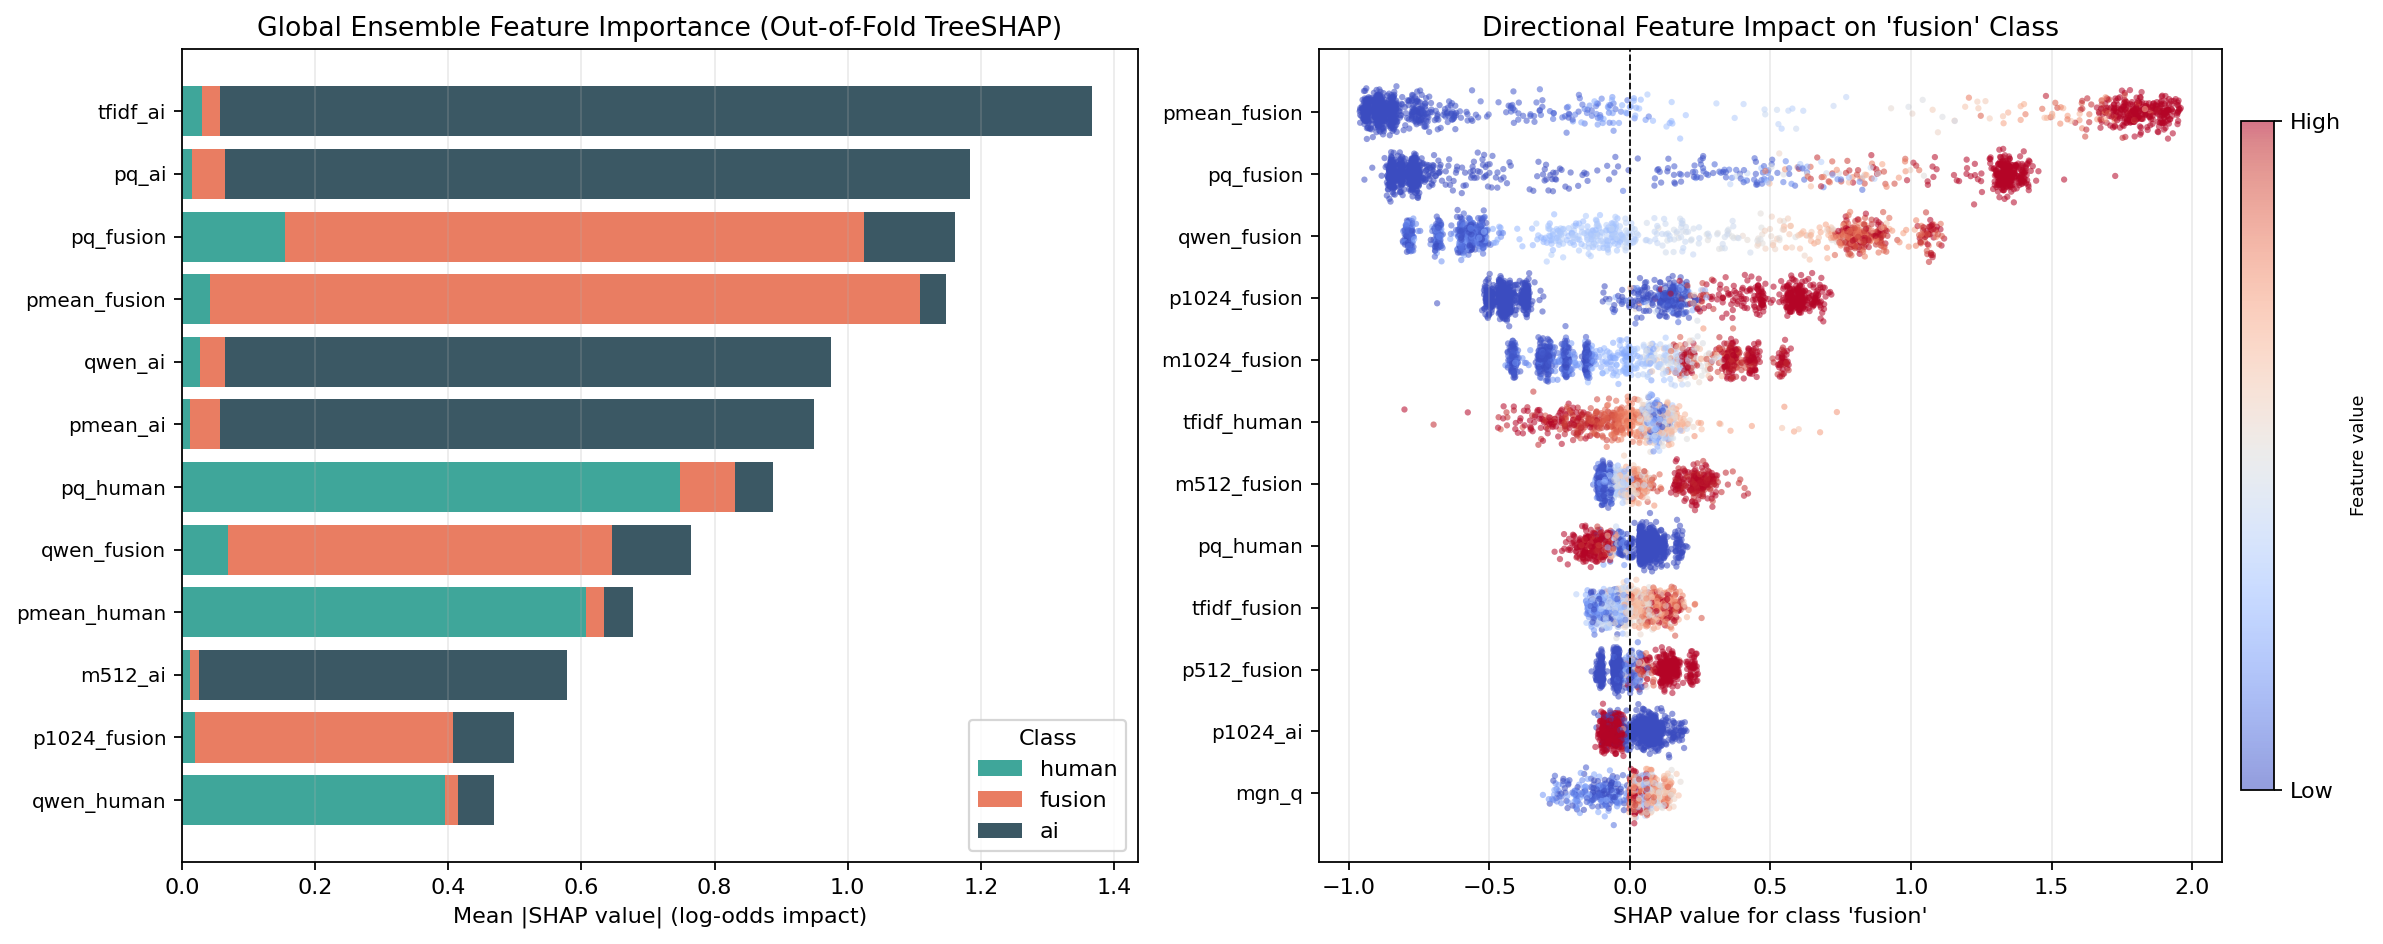


--- Global SHAP Share by Feature Group (%) ---
Qwen2.5-1.5B LoRA             32.35
Ensemble Agreement / Diffs    17.99
TF-IDF Linear Baseline        12.93
mDeBERTa-1024                 12.76
mDeBERTa-512                  11.52
Qwen-0.5B Perplexity (40)      9.94
Text Stylometry Meta (8)       2.51

--- Selected 6 Representative Cases for Deep xAI ---
            tag     id                 domain  lang  n_words  y_true true_label  ens_pred pred_label   p_H   p_F  p_A qwen_pred m1024_pred  ppl_range
    TP_human_en d2eb55               cnn_news en-EN      415       0      human         0      human 1.000 0.000  0.0     human      human      3.381
   TP_fusion_en 0da0e2         student_essays en-EN      471       1     fusion         1     fusion 0.000 1.000  0.0    fusion     fusion      4.352
       TP_ai_en 20a5d5       euro_court_cases en-EN      337       2         ai         2         ai 0.000 0.000  1.0        ai         ai      1.860
   TP_fusion_de cb9e9c              bundestag 

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

DATA_DIR = Path("/kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026")
BASE_DIR = Path("/kaggle/input/notebooks/oleksandrtsybrivskyi/01-eda-split-baseline")
M512_DIR = Path("/kaggle/input/notebooks/oleksandrtsybrivskyi/02-transformer-training")
M1024_DIR = Path("/kaggle/input/notebooks/oleksandrtsybrivskyi/03-error-analysis-and-ensemble")
QWEN_DIR = Path("/kaggle/input/notebooks/oleksandrtsybrivskyi/05-qwen-lora")
PPL_DIR = Path("/kaggle/input/notebooks/oleksandrtsybrivskyi/06-qwen-perplexity")
OUT_DIR = Path("/kaggle/working")

CLASSES = ["human", "fusion", "ai"]
LABEL2ID = {c: i for i, c in enumerate(CLASSES)}
SCORE_COLS_B = [f"score_{c}" for c in CLASSES]
LOGIT_COLS = [f"logit_{c}" for c in CLASSES]

train = pd.read_csv(DATA_DIR / "train.csv")
splits = pd.read_parquet(BASE_DIR / "folds.parquet")
assert (train["id"].to_numpy() == splits["id"].to_numpy()).all()
train["fold"] = splits["fold"].to_numpy()
train["y"] = train["label"].map(LABEL2ID).astype(np.int64)

va = train[train["fold"] == 0].reset_index(drop=True)
va_ids = va["id"].to_numpy()
y_va = va["y"].to_numpy()
lang_col = next(c for c in ("language", "lang") if c in va.columns)

def load_aligned(path: Path, ref_ids: np.ndarray) -> pd.DataFrame:
    df = pd.read_parquet(path).set_index("id").loc[ref_ids].reset_index()
    assert (df["id"].to_numpy() == ref_ids).all()
    return df

base_va = load_aligned(BASE_DIR / "baseline_oof_fold0.parquet", va_ids)
m512_va = load_aligned(M512_DIR / "mdeberta_oof_fold0.parquet", va_ids)
m1024_va = load_aligned(M1024_DIR / "mdeberta_long_oof_fold0.parquet", va_ids)
qwen_va = load_aligned(QWEN_DIR / "qwen15b_lora_oof_fold0.parquet", va_ids)
ppl_va = load_aligned(PPL_DIR / "qwen_ppl_oof_fold0.parquet", va_ids)

def softmax(x):
    e = np.exp(x - x.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def entropy(p):
    return -(p * np.log(np.clip(p, 1e-12, 1.0))).sum(axis=1, keepdims=True)

def top_margin(x):
    s = np.sort(x, axis=1)
    return (s[:, -1] - s[:, -2])[:, None]

def text_meta(texts: pd.Series):
    s = texts.fillna("")
    n_chars = s.str.len().to_numpy(np.float64)
    n_words = s.str.split().str.len().to_numpy(np.float64)
    n_lines = (s.str.count("\n") + 1).to_numpy(np.float64)
    n_upper = s.str.count(r"[A-ZÄÖÜ]").to_numpy(np.float64)
    n_punct = s.str.count(r"[.,;:!?\"'()-]").to_numpy(np.float64)
    n_digits = s.str.count(r"\d").to_numpy(np.float64)
    arr = np.column_stack([
        np.log1p(n_chars), np.log1p(n_words), n_chars / np.maximum(n_words, 1.0),
        np.log1p(n_lines), n_words / np.maximum(n_lines, 1.0),
        n_upper / np.maximum(n_chars, 1.0), n_punct / np.maximum(n_chars, 1.0), n_digits / np.maximum(n_chars, 1.0),
    ])
    names = ["log_chars", "log_words", "avg_word_len", "log_lines", "words_per_line", "upper_rate", "punct_rate", "digit_rate"]
    return arr, names

S_b = base_va[SCORE_COLS_B].to_numpy(np.float64)
L_512 = m512_va[LOGIT_COLS].to_numpy(np.float64)
L_1024 = m1024_va[LOGIT_COLS].to_numpy(np.float64)
L_q = qwen_va[LOGIT_COLS].to_numpy(np.float64)
pq, p1024, p512 = softmax(L_q), softmax(L_1024), softmax(L_512)

inter = np.hstack([
    pq, p1024, p512,
    entropy(pq), entropy(p1024), entropy(p512),
    top_margin(L_q), top_margin(L_1024), top_margin(L_512), top_margin(S_b),
    pq - p1024,
    np.abs(pq - p1024).sum(axis=1, keepdims=True),
    np.abs(pq - p512).sum(axis=1, keepdims=True),
    np.abs(p1024 - p512).sum(axis=1, keepdims=True),
    (pq + p1024 + p512) / 3.0,
])
inter_cols = (
    [f"pq_{c}" for c in CLASSES] + [f"p1024_{c}" for c in CLASSES] + [f"p512_{c}" for c in CLASSES]
    + ["ent_q", "ent_1024", "ent_512", "mgn_q", "mgn_1024", "mgn_512", "mgn_b"]
    + [f"diff_q_1024_{c}" for c in CLASSES]
    + ["l1_q_1024", "l1_q_512", "l1_1024_512"]
    + [f"pmean_{c}" for c in CLASSES]
)
ppl_cols = [c for c in ppl_va.columns if c != "id"]
F_meta, meta_cols = text_meta(va["text"])
feat_names = (
    [f"qwen_{c}" for c in CLASSES] + [f"m1024_{c}" for c in CLASSES]
    + [f"m512_{c}" for c in CLASSES] + [f"tfidf_{c}" for c in CLASSES]
    + inter_cols + ppl_cols + meta_cols
)
X_df = pd.DataFrame(
    np.hstack([L_q, L_1024, L_512, S_b, inter, ppl_va[ppl_cols].to_numpy(np.float64), F_meta]),
    columns=feat_names,
)

# 1. Nested 5-fold OOF для чесного відбору помилок + точний TreeSHAP
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_prob = np.zeros((len(y_va), 3), dtype=np.float64)
shap_parts, shap_idx_parts = [], []

for tr_i, ev_i in skf.split(X_df, y_va):
    clf = LGBMClassifier(
        n_estimators=550, learning_rate=0.03, num_leaves=31,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.75,
        min_child_samples=80, reg_alpha=1.0, reg_lambda=3.0,
        random_state=42, n_jobs=-1, verbose=-1,
    )
    clf.fit(X_df.iloc[tr_i], y_va[tr_i])
    oof_prob[ev_i] = clf.predict_proba(X_df.iloc[ev_i])

    # Рахуємо TreeSHAP строго out-of-fold на стратифікованій вибірці (1000 рядків/фолд = 5000 разом)
    rng = np.random.default_rng(42)
    sub_i = rng.choice(ev_i, size=min(1000, len(ev_i)), replace=False)
    raw_c = clf.predict(X_df.iloc[sub_i], pred_contrib=True)
    n_f = X_df.shape[1]
    if isinstance(raw_c, list):
        sv = np.stack([a[:, :n_f] for a in raw_c], axis=1)
    elif raw_c.ndim == 3:
        sv = raw_c[:, :, :n_f]
    else:
        sv = raw_c.reshape(len(sub_i), 3, n_f + 1)[:, :, :n_f]
    shap_parts.append(sv)
    shap_idx_parts.append(sub_i)

oof_pred = oof_prob.argmax(axis=1)
print(f"LGBM Meta-Model OOF Macro-F1: {f1_score(y_va, oof_pred, average='macro'):.4f}")

shap_all = np.concatenate(shap_parts, axis=0)   # (5000, 3, F)
shap_idx = np.concatenate(shap_idx_parts, axis=0)
X_shap = X_df.iloc[shap_idx].reset_index(drop=True)

# 2. Графік 1: Глобальний TreeSHAP (Top-12 по класах + вплив на клас fusion)
mean_abs = np.abs(shap_all).mean(axis=0)  # (3, F)
total_imp = mean_abs.sum(axis=0)
top_k = 12
top_idx = np.argsort(total_imp)[-top_k:]
top_names = [feat_names[i] for i in top_idx]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=160)
colors = {"human": "#2a9d8f", "fusion": "#e76f51", "ai": "#264653"}
left = np.zeros(top_k)
for c_i, c_name in enumerate(CLASSES):
    vals = mean_abs[c_i, top_idx]
    ax1.barh(range(top_k), vals, left=left, color=colors[c_name], label=c_name, alpha=0.9)
    left += vals
ax1.set_yticks(range(top_k))
ax1.set_yticklabels(top_names, fontsize=9)
ax1.set_xlabel("Mean |SHAP value| (log-odds impact)")
ax1.set_title("Global Ensemble Feature Importance (Out-of-Fold TreeSHAP)")
ax1.legend(title="Class", loc="lower right")
ax1.grid(axis="x", alpha=0.25)

# Beeswarm-подібний scatter для класу fusion (найскладніша межа)
fusion_top_idx = np.argsort(mean_abs[1])[-top_k:]
fusion_top_names = [feat_names[i] for i in fusion_top_idx]
rng = np.random.default_rng(7)
sample_pts = rng.choice(len(X_shap), size=1200, replace=False)
for row_pos, f_i in enumerate(fusion_top_idx):
    sv_f = shap_all[sample_pts, 1, f_i]
    fv = X_shap.iloc[sample_pts, f_i].to_numpy()
    q05, q95 = np.percentile(fv, [5, 95])
    fv_norm = np.clip((fv - q05) / max(q95 - q05, 1e-9), 0, 1)
    jitter = rng.normal(0, 0.14, size=len(sample_pts))
    sc = ax2.scatter(sv_f, row_pos + jitter, c=fv_norm, cmap="coolwarm", s=8, alpha=0.55, edgecolors="none")
ax2.axvline(0, color="black", lw=0.8, ls="--")
ax2.set_yticks(range(top_k))
ax2.set_yticklabels(fusion_top_names, fontsize=9)
ax2.set_xlabel("SHAP value for class 'fusion'")
ax2.set_title("Directional Feature Impact on 'fusion' Class")
ax2.grid(axis="x", alpha=0.25)
cbar = fig.colorbar(sc, ax=ax2, fraction=0.035, pad=0.02)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Low", "High"])
cbar.set_label("Feature value", fontsize=8)

plt.tight_layout()
plt.savefig(OUT_DIR / "xai_01_shap_global.png", bbox_inches="tight")
plt.show()

# Внесок по групах ознак (для таблиці у звіт)
groups = {
    "Qwen2.5-1.5B LoRA": [i for i, n in enumerate(feat_names) if n.startswith(("qwen_", "pq_", "ent_q", "mgn_q")) and not n.startswith("qwen_n_") and not n.startswith("qwen_nll") and not n.startswith("qwen_ent") and not n.startswith("qwen_surp") and not n.startswith("qwen_logrank") and not n.startswith("qwen_top") and not n.startswith("qwen_win") and not n.startswith("qwen_q") and not n.startswith("qwen_head") and not n.startswith("qwen_mid") and n != "qwen_truncated"],
    "mDeBERTa-1024": [i for i, n in enumerate(feat_names) if n.startswith(("m1024_", "p1024_", "ent_1024", "mgn_1024"))],
    "mDeBERTa-512": [i for i, n in enumerate(feat_names) if n.startswith(("m512_", "p512_", "ent_512", "mgn_512"))],
    "Ensemble Agreement / Diffs": [i for i, n in enumerate(feat_names) if n.startswith(("pmean_", "diff_", "l1_"))],
    "TF-IDF Linear Baseline": [i for i, n in enumerate(feat_names) if n.startswith(("tfidf_", "mgn_b"))],
    "Qwen-0.5B Perplexity (40)": [i for i, n in enumerate(feat_names) if n in ppl_cols],
    "Text Stylometry Meta (8)": [i for i, n in enumerate(feat_names) if n in meta_cols],
}
grp_imp = pd.Series({k: total_imp[v].sum() for k, v in groups.items()}).sort_values(ascending=False)
print("\n--- Global SHAP Share by Feature Group (%) ---")
print((grp_imp / grp_imp.sum() * 100).round(2).to_string())

# 3. Відбір 6 показових прикладів із Val Fold 0
va["n_words"] = va["text"].str.split().str.len()
va["ens_pred"] = oof_pred
va["ens_conf"] = oof_prob.max(axis=1)
va["qwen_pred"] = qwen_va["y_pred"].to_numpy()
va["m1024_pred"] = m1024_va["y_pred"].to_numpy()
va["tfidf_pred"] = base_va["y_pred"].to_numpy()
va["ppl_range"] = ppl_va["qwen_win_nll_range"].to_numpy()
for c_i, c_name in enumerate(CLASSES):
    va[f"p_{c_name}"] = oof_prob[:, c_i]

def pick_one(mask, sort_col, ascending=False):
    sub = va[mask].sort_values(sort_col, ascending=ascending)
    assert len(sub) > 0, "Empty selection mask!"
    return int(sub.index[0])

selected_rows = [
    ("TP_human_en", pick_one((va["y"] == 0) & (va["ens_pred"] == 0) & (va[lang_col] == "en-EN") & va["n_words"].between(180, 420), "ens_conf", False)),
    ("TP_fusion_en", pick_one((va["y"] == 1) & (va["ens_pred"] == 1) & (va[lang_col] == "en-EN") & va["n_words"].between(220, 480) & (va["ens_conf"] > 0.95), "ppl_range", False)),
    ("TP_ai_en", pick_one((va["y"] == 2) & (va["ens_pred"] == 2) & (va[lang_col] == "en-EN") & va["n_words"].between(180, 420), "ens_conf", False)),
    ("TP_fusion_de", pick_one((va["y"] == 1) & (va["ens_pred"] == 1) & (va[lang_col] == "de-DE") & va["n_words"].between(220, 480) & (va["ens_conf"] > 0.95), "ppl_range", False)),
    ("ERR_blog_F_as_H", pick_one((va["domain"] == "blog_authorship_corpus") & (va["y"] == 1) & (va["ens_pred"] == 0) & (va["qwen_pred"] == 0) & va["n_words"].between(120, 350), "ens_conf", False)),
    ("ERR_long_H_as_F", pick_one((va["y"] == 0) & (va["ens_pred"] == 1) & (va["qwen_pred"] == 1) & va["n_words"].between(350, 750), "ens_conf", False)),
]

selected_cases = []
for tag, row_i in selected_rows:
    r = va.iloc[row_i]
    selected_cases.append({
        "tag": tag, "row_idx": row_i, "id": r["id"], "domain": r["domain"],
        "lang": r[lang_col], "n_words": int(r["n_words"]),
        "y_true": int(r["y"]), "true_label": CLASSES[int(r["y"])],
        "ens_pred": int(r["ens_pred"]), "pred_label": CLASSES[int(r["ens_pred"])],
        "p_H": round(float(r["p_human"]), 3), "p_F": round(float(r["p_fusion"]), 3), "p_A": round(float(r["p_ai"]), 3),
        "qwen_pred": CLASSES[int(r["qwen_pred"])], "m1024_pred": CLASSES[int(r["m1024_pred"])],
        "ppl_range": round(float(r["ppl_range"]), 3),
        "text": r["text"],
    })

cases_df = pd.DataFrame(selected_cases)
cases_df.drop(columns=["text"]).to_csv(OUT_DIR / "xai_selected_cases.csv", index=False)
print("\n--- Selected 6 Representative Cases for Deep xAI ---")
print(cases_df.drop(columns=["text", "row_idx"]).to_string(index=False))

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

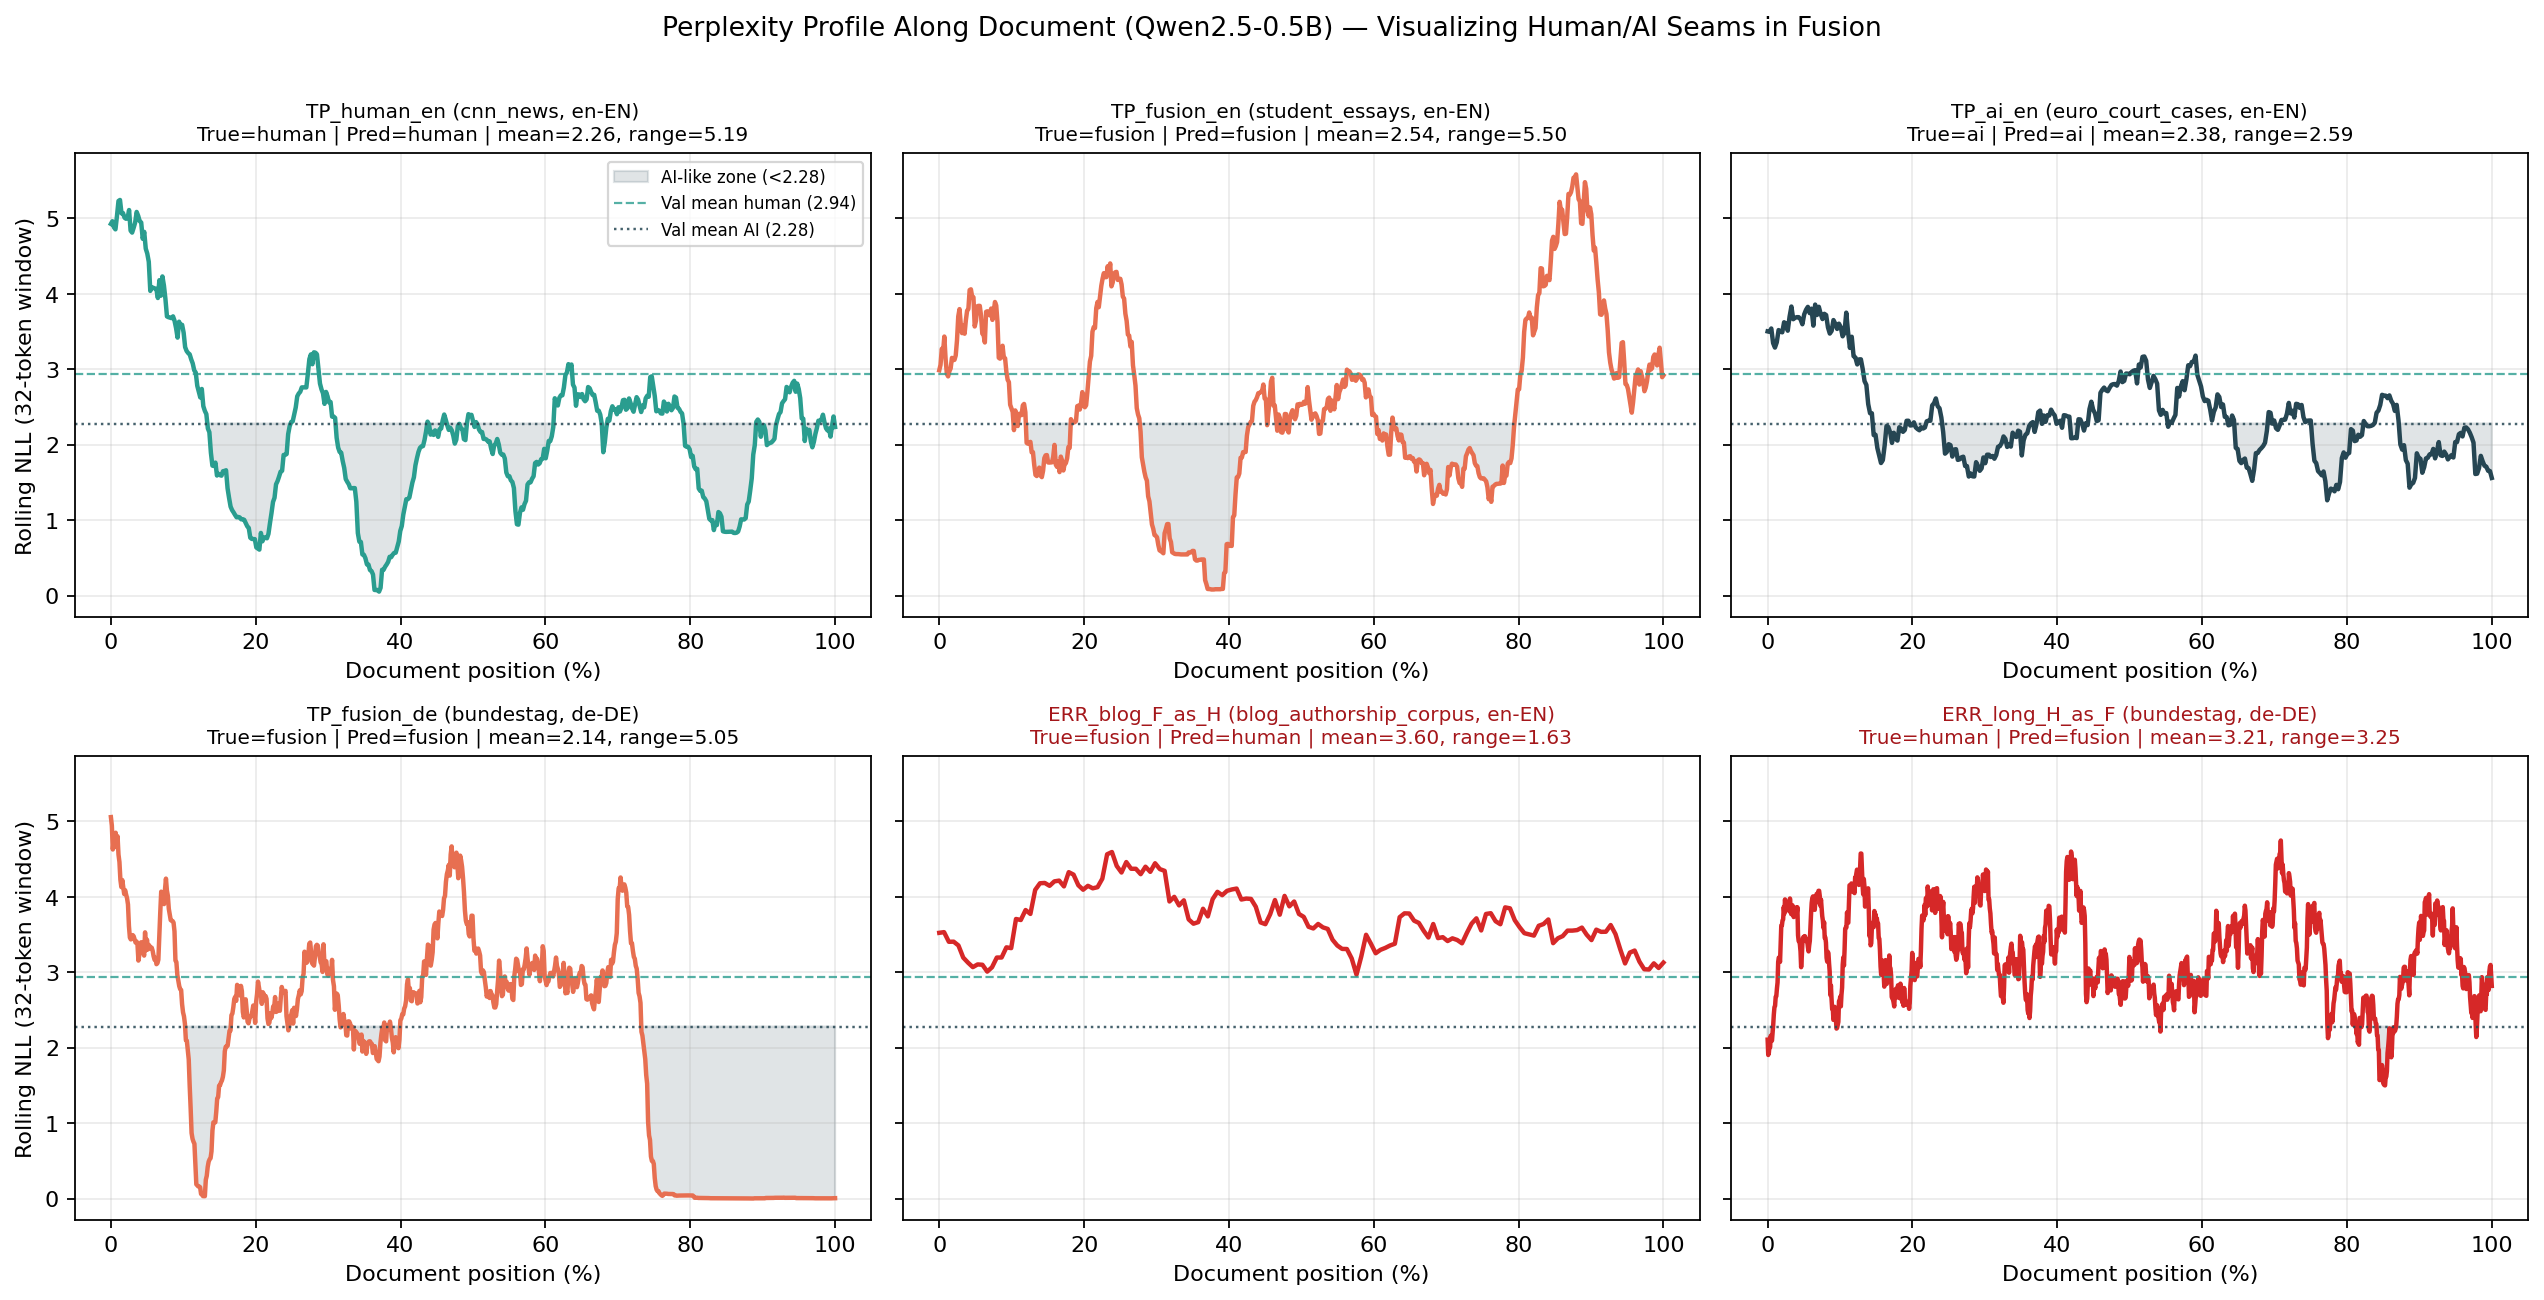

In [2]:
import gc
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ppl_model_name = "Qwen/Qwen2.5-0.5B"
ppl_tok = AutoTokenizer.from_pretrained(ppl_model_name)
ppl_model = AutoModelForCausalLM.from_pretrained(ppl_model_name, torch_dtype=torch.float16).to(device).eval()

@torch.no_grad()
def token_nll_curve(text: str, max_len: int = 1200, win: int = 32):
    ids = ppl_tok.encode(text, add_special_tokens=False)[:max_len]
    input_ids = torch.tensor([ids], dtype=torch.long, device=device)
    with torch.amp.autocast("cuda", dtype=torch.float16):
        hidden = ppl_model.model(input_ids=input_ids, use_cache=False).last_hidden_state[0, :-1]
    y = input_ids[0, 1:]
    nlls = []
    for s in range(0, len(y), 256):
        logits = ppl_model.lm_head(hidden[s : s + 256]).float()
        lp = F.log_softmax(logits, dim=-1)
        nlls.append(-lp.gather(1, y[s : s + 256].unsqueeze(1)).squeeze(1).cpu().numpy())
    nll = np.concatenate(nlls)
    if len(nll) >= win:
        kernel = np.ones(win) / win
        smooth = np.convolve(nll, kernel, mode="valid")
    else:
        smooth = nll
    pos_pct = np.linspace(0, 100, len(smooth))
    return pos_pct, smooth, float(nll.mean()), float(smooth.max() - smooth.min())

fig, axes = plt.subplots(2, 3, figsize=(16, 8), dpi=160, sharey=True)
for ax, case in zip(axes.flat, selected_cases):
    x_pos, curve, mean_nll, rng_nll = token_nll_curve(case["text"])
    is_err = case["y_true"] != case["ens_pred"]
    col = "#d62828" if is_err else colors[case["true_label"]]
    ax.plot(x_pos, curve, color=col, lw=2.0)
    ax.fill_between(x_pos, curve, 2.28, where=(curve < 2.28), color="#264653", alpha=0.14, label="AI-like zone (<2.28)")
    ax.axhline(2.94, color="#2a9d8f", ls="--", lw=1.0, alpha=0.8, label="Val mean human (2.94)")
    ax.axhline(2.28, color="#264653", ls=":", lw=1.1, alpha=0.85, label="Val mean AI (2.28)")
    ax.set_title(
        f"{case['tag']} ({case['domain']}, {case['lang']})\n"
        f"True={case['true_label']} | Pred={case['pred_label']} | mean={mean_nll:.2f}, range={rng_nll:.2f}",
        fontsize=9,
        color="#a4161a" if is_err else "black",
    )
    ax.set_xlabel("Document position (%)")
    ax.grid(alpha=0.25)

axes[0, 0].set_ylabel("Rolling NLL (32-token window)")
axes[1, 0].set_ylabel("Rolling NLL (32-token window)")
axes[0, 0].legend(fontsize=7.5, loc="upper right")
fig.suptitle("Perplexity Profile Along Document (Qwen2.5-0.5B) — Visualizing Human/AI Seams in Fusion", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "xai_02_perplexity_profiles.png", bbox_inches="tight")
plt.show()

del ppl_model, ppl_tok
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[TP_human_en] target=human | max_logit_diff=0.0051 | IG_completeness_rel_err=0.014
[TP_fusion_en] target=fusion | max_logit_diff=0.0026 | IG_completeness_rel_err=1.549
[TP_ai_en] target=ai | max_logit_diff=0.0039 | IG_completeness_rel_err=2.457
[TP_fusion_de] target=fusion | max_logit_diff=0.0070 | IG_completeness_rel_err=1.471
[ERR_blog_F_as_H] target=human | max_logit_diff=0.0014 | IG_completeness_rel_err=0.031
[ERR_long_H_as_F] target=fusion | max_logit_diff=0.0023 | IG_completeness_rel_err=0.011


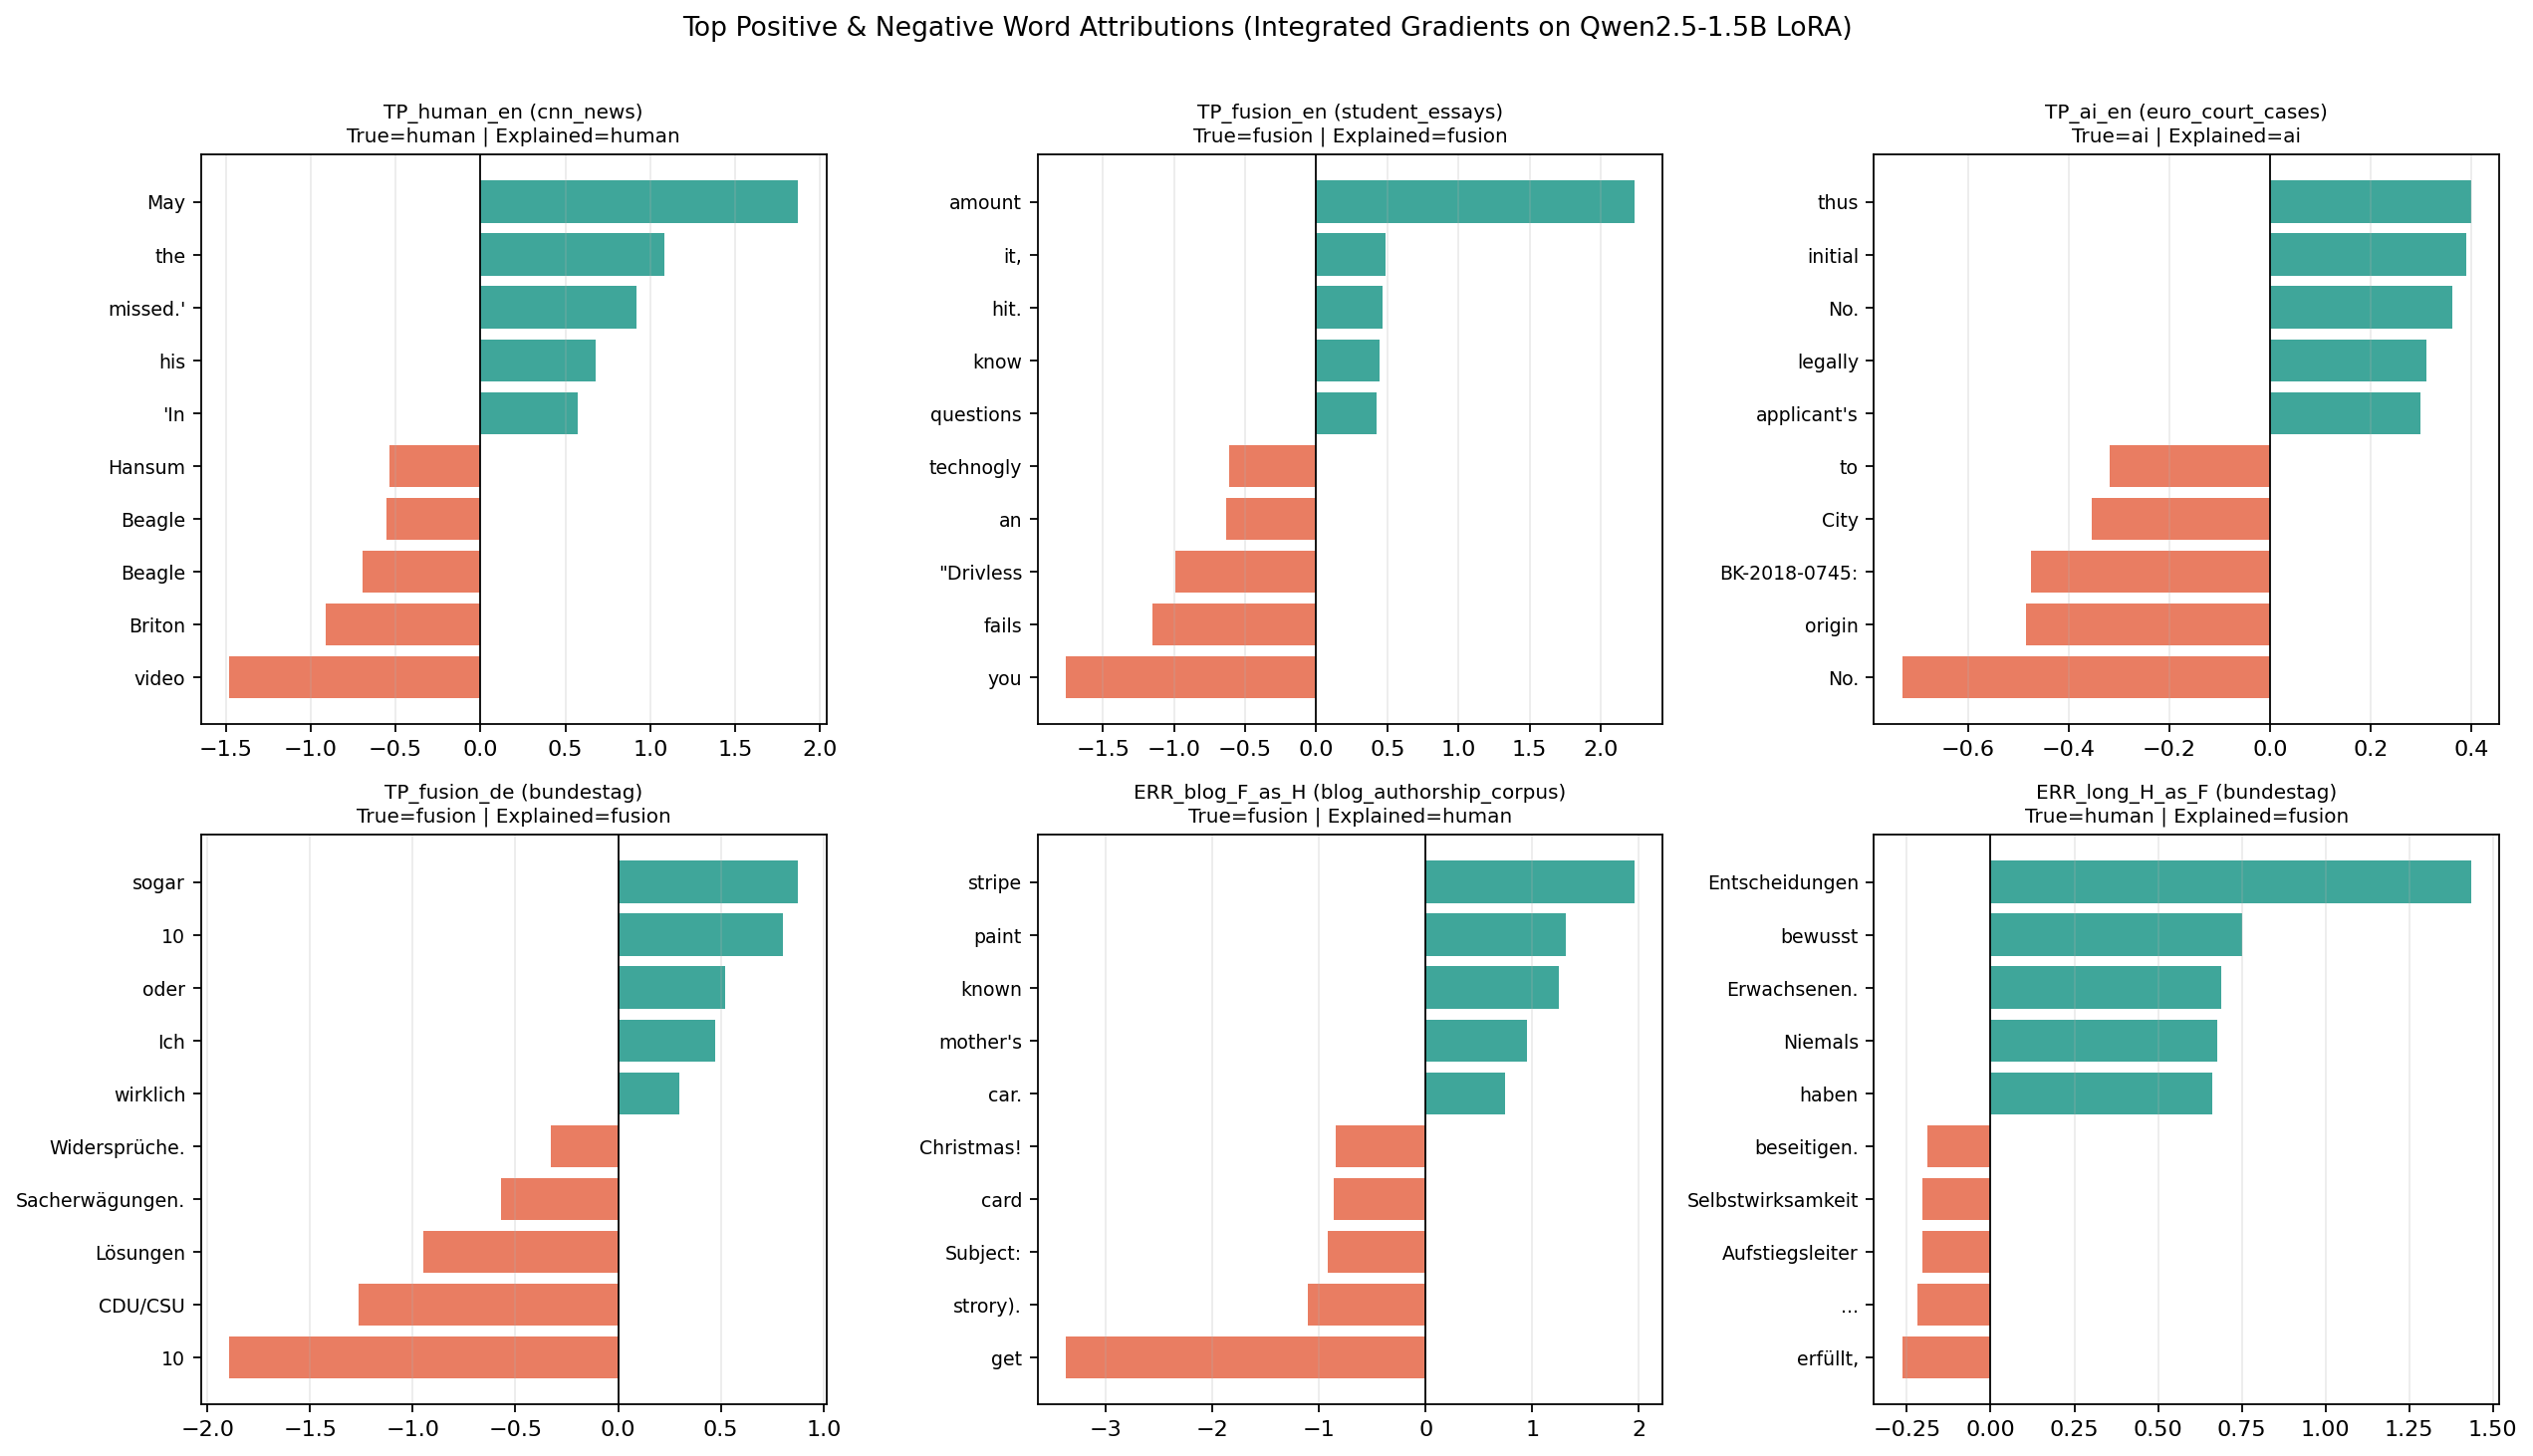

Saved clean xai_03_top_tokens.png and xai_03_token_attributions.html


In [6]:
import gc
import html
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import HTML, display
from transformers import AutoModel, AutoTokenizer

for _var in ("q_model", "backbone"):
    if _var in globals():
        del globals()[_var]
gc.collect()
torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LORA_TARGETS = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")

class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r: int = 16, alpha: int = 32):
        super().__init__()
        self.base = base
        self.scaling = alpha / r
        self.lora_A = nn.Parameter(torch.empty(r, base.in_features, dtype=torch.float32))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r, dtype=torch.float32))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.base(x) + F.linear(F.linear(x, self.lora_A), self.lora_B) * self.scaling

def inject_lora(model: nn.Module, r: int = 16, alpha: int = 32):
    for name, module in list(model.named_modules()):
        leaf = name.split(".")[-1]
        if leaf in LORA_TARGETS and isinstance(module, nn.Linear):
            parent = model.get_submodule(".".join(name.split(".")[:-1])) if "." in name else model
            setattr(parent, leaf, LoRALinear(module, r=r, alpha=alpha))

class QwenClassifier(nn.Module):
    def __init__(self, backbone: nn.Module, num_labels: int = 3):
        super().__init__()
        self.backbone = backbone
        h = backbone.config.hidden_size
        self.norm = nn.LayerNorm(h * 2, dtype=torch.float32)
        self.drop = nn.Identity()
        self.head = nn.Linear(h * 2, num_labels, dtype=torch.float32)

    def forward(self, input_ids=None, attention_mask=None, inputs_embeds=None):
        hs = self.backbone(
            input_ids=input_ids, inputs_embeds=inputs_embeds,
            attention_mask=attention_mask, use_cache=False
        ).last_hidden_state
        mask = attention_mask.unsqueeze(-1).float()
        mean_pool = (hs * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)
        last_idx = (attention_mask.sum(dim=1) - 1).clamp(min=0)
        last_pool = hs[torch.arange(hs.size(0), device=hs.device), last_idx]
        return self.head(self.drop(self.norm(torch.cat([last_pool, mean_pool], dim=-1))))

q_name = "Qwen/Qwen2.5-1.5B"
q_tok = AutoTokenizer.from_pretrained(q_name)
if q_tok.pad_token_id is None:
    q_tok.pad_token_id = q_tok.eos_token_id
sep_ids = q_tok.encode("\n...\n", add_special_tokens=False) or [q_tok.eos_token_id]

# Чистий FP32 (~7.5 GB VRAM із gradient checkpointing) — нуль FP16 overflow
backbone = AutoModel.from_pretrained(q_name, torch_dtype=torch.float32, attn_implementation="sdpa")
inject_lora(backbone, r=16, alpha=32)
backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
q_model = QwenClassifier(backbone, num_labels=3).to(device)
adapter_state = torch.load(QWEN_DIR / "qwen15b_lora_adapter.pt", map_location=device, weights_only=True)
_, unexpected = q_model.load_state_dict(adapter_state, strict=False)
assert len(unexpected) == 0, f"Unexpected keys: {unexpected}"
for p in q_model.parameters():
    p.requires_grad_(False)
q_model.eval()

def encode_long(text: str, max_len: int = 1024):
    ids = q_tok.encode(text, add_special_tokens=False) or [q_tok.eos_token_id]
    if len(ids) > max_len:
        budget = max_len - 2 * len(sep_ids)
        h, m = budget // 3, budget // 3
        t = budget - h - m
        ms = (len(ids) - m) // 2
        ids = ids[:h] + sep_ids + ids[ms : ms + m] + sep_ids + ids[-t:]
    return ids

def integrated_gradients_words(text: str, target_cls: int, ref_logits=None, steps: int = 24):
    ids = encode_long(text, max_len=1024)
    input_ids = torch.tensor([ids], dtype=torch.long, device=device)
    attn_mask = torch.ones_like(input_ids)
    emb_layer = q_model.backbone.get_input_embeddings()

    with torch.no_grad():
        embeds = emb_layer(input_ids).detach()
        baseline = emb_layer(torch.full_like(input_ids, q_tok.pad_token_id)).detach()
        logits_real = q_model(inputs_embeds=embeds, attention_mask=attn_mask)[0].cpu().numpy()
        logits_base = q_model(inputs_embeds=baseline, attention_mask=attn_mask)[0].cpu().numpy()

    logit_err = float(np.abs(logits_real - ref_logits).max()) if ref_logits is not None else 0.0

    # Правило середніх точок у точному FP32
    total_grad = torch.zeros_like(embeds)
    alphas = (np.arange(steps) + 0.5) / steps
    for alpha in alphas:
        scaled = (baseline + float(alpha) * (embeds - baseline)).detach().requires_grad_(True)
        score = q_model(inputs_embeds=scaled, attention_mask=attn_mask)[0, target_cls]
        total_grad += torch.autograd.grad(score, scaled)[0].detach()

    tok_attr = ((embeds - baseline) * (total_grad / steps)).sum(dim=-1)[0].cpu().numpy()
    assert np.isfinite(tok_attr).all(), "Non-finite attribution detected!"
    delta = float(logits_real[target_cls] - logits_base[target_cls])
    completeness_err = abs(float(tok_attr.sum()) - delta) / max(abs(delta), 1e-6)

    words, scores = [], []
    cur_ids, cur_score = [], 0.0
    for tid, sc in zip(ids, tok_attr):
        piece = q_tok.decode([tid], skip_special_tokens=False)
        starts_new = (len(cur_ids) > 0) and (piece.startswith((" ", "\n", "\t")) or piece.strip() == "")
        if starts_new and "\ufffd" not in q_tok.decode(cur_ids):
            words.append(q_tok.decode(cur_ids))
            scores.append(cur_score)
            cur_ids, cur_score = [tid], float(sc)
        else:
            cur_ids.append(tid)
            cur_score += float(sc)
    if cur_ids:
        words.append(q_tok.decode(cur_ids))
        scores.append(cur_score)

    return words, np.array(scores, dtype=np.float32), logits_real, logit_err, completeness_err

ig_results = []
html_blocks = [
    "<html><head><meta charset='utf-8'><style>"
    "body{font-family:system-ui,sans-serif;max-width:960px;margin:20px auto;line-height:1.65;color:#111}"
    ".card{border:1px solid #ddd;border-radius:8px;padding:14px 18px;margin-bottom:18px}"
    ".meta{font-size:13px;color:#444;margin-bottom:8px;border-bottom:1px solid #eee;padding-bottom:6px}"
    ".tok{padding:1px 2px;border-radius:3px}"
    "</style></head><body><h2>Token-Level Integrated Gradients (Qwen2.5-1.5B LoRA)</h2>"
    "<p><b>Green</b> = pushes toward predicted class; <b>Red</b> = pushes against predicted class.</p>"
]

for case in selected_cases:
    ref_l = qwen_va.iloc[case["row_idx"]][LOGIT_COLS].to_numpy(np.float32)
    target_c = case["ens_pred"]
    words, scores, l_real, l_err, comp_err = integrated_gradients_words(case["text"], target_c, ref_logits=ref_l, steps=24)
    ig_results.append((case, words, scores, l_err, comp_err))
    print(f"[{case['tag']}] target={CLASSES[target_c]} | max_logit_diff={l_err:.4f} | IG_completeness_rel_err={comp_err:.3f}")

    scale = float(np.percentile(np.abs(scores), 97)) + 1e-6
    spans = []
    for w, sc in zip(words[:220], scores[:220]):
        norm = float(np.clip(sc / scale, -1.0, 1.0))
        alpha = min(0.75, abs(norm) * 0.75)
        bg = f"rgba(42,157,143,{alpha:.2f})" if norm >= 0 else f"rgba(231,111,81,{alpha:.2f})"
        safe_w = html.escape(w).replace("\n", "<br>")
        spans.append(f"<span class='tok' style='background:{bg}'>{safe_w}</span>")
    if len(words) > 220:
        spans.append(" <i>[... truncated for display ...]</i>")

    html_blocks.append(
        f"<div class='card'><div class='meta'><b>{case['tag']}</b> | domain: <b>{case['domain']}</b> ({case['lang']}) | "
        f"True: <b>{case['true_label']}</b> | Pred: <b>{case['pred_label']}</b> "
        f"(H={case['p_H']}, F={case['p_F']}, A={case['p_A']})</div><div>{''.join(spans)}</div></div>"
    )

html_blocks.append("</body></html>")
html_str = "\n".join(html_blocks)
(OUT_DIR / "xai_03_token_attributions.html").write_text(html_str, encoding="utf-8")

fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=160)
for ax, (case, words, scores, _, _) in zip(axes.flat, ig_results):
    clean = [(w.strip().replace("\n", " "), float(s)) for w, s in zip(words, scores) if len(w.strip()) >= 2]
    clean.sort(key=lambda x: x[1])
    shown = clean[:5] + clean[-5:]
    ax.barh(range(len(shown)), [s for _, s in shown], color=["#e76f51" if s < 0 else "#2a9d8f" for _, s in shown], alpha=0.9)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(shown)))
    ax.set_yticklabels([w[:18] for w, _ in shown], fontsize=8.5)
    ax.set_title(f"{case['tag']} ({case['domain']})\nTrue={case['true_label']} | Explained={case['pred_label']}", fontsize=9)
    ax.grid(axis="x", alpha=0.25)

fig.suptitle("Top Positive & Negative Word Attributions (Integrated Gradients on Qwen2.5-1.5B LoRA)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "xai_03_top_tokens.png", bbox_inches="tight")
plt.show()
print("Saved clean xai_03_top_tokens.png and xai_03_token_attributions.html")
display(HTML(html_str))